## Predicción de divorcio con análisis factorial

Cuaderno complementario del **capítulo 3** de las notas (sección 3.8, *Un ejemplo de advertencia*). Datos: *Divorce Predictors* (Yöntem et al., 2019): 170 parejas en Turquía respondieron 54 reactivos inspirados en la investigación de Gottman; 84 se divorciaron.

In [1]:
# Bibliotecas

import pandas as pd
pd.options.display.max_columns = 100
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('ggplot')
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")


Cada reactivo se responde en una escala de **0 (más bajo) a 4 (más alto)**. La última columna, `Divorce_Y_N`, indica si la pareja se divorció (1) o no (0).

1. Si uno de nosotros se disculpa cuando la discusión se deteriora, la discusión termina.
2. Sé que podemos ignorar nuestras diferencias, aunque a veces las cosas se pongan difíciles.
3. Cuando lo necesitamos, podemos retomar nuestras discusiones desde el principio y corregirlas.
4. Cuando discuto con mi pareja, buscar el contacto termina por funcionar.
5. El tiempo que paso con mi pareja es especial para nosotros.
6. No tenemos tiempo en casa como pareja.
7. Somos como dos extraños que comparten el mismo espacio en casa más que una familia.
8. Disfruto nuestras vacaciones con mi pareja.
9. Disfruto viajar con mi pareja.
10. La mayoría de nuestras metas son comunes.
11. Creo que algún día, al mirar atrás, veré que mi pareja y yo estuvimos en armonía.
12. Mi pareja y yo tenemos valores similares en cuanto a la libertad personal.
13. Mi pareja y yo tenemos un sentido similar del entretenimiento.
14. La mayoría de nuestras metas respecto a otras personas (hijos, amigos, etc.) son las mismas.
15. Nuestros sueños son similares y armoniosos.
16. Somos compatibles en lo que debe ser el amor.
17. Compartimos la misma visión sobre ser felices en nuestra vida.
18. Mi pareja y yo tenemos ideas similares sobre cómo debe ser el matrimonio.
19. Mi pareja y yo tenemos ideas similares sobre los roles en el matrimonio.
20. Mi pareja y yo tenemos valores similares en cuanto a la confianza.
21. Sé exactamente lo que le gusta a mi pareja.
22. Sé cómo quiere ser cuidada mi pareja cuando está enferma.
23. Conozco la comida favorita de mi pareja.
24. Puedo decir qué tipo de estrés enfrenta mi pareja en su vida.
25. Conozco el mundo interior de mi pareja.
26. Conozco las ansiedades básicas de mi pareja.
27. Sé cuáles son las fuentes actuales de estrés de mi pareja.
28. Conozco las esperanzas y deseos de mi pareja.
29. Conozco muy bien a mi pareja.
30. Conozco a los amigos de mi pareja y sus relaciones sociales.
31. Me siento agresivo cuando discuto con mi pareja.
32. Al discutir con mi pareja, suelo usar expresiones como "tú siempre" o "tú nunca".
33. Puedo usar afirmaciones negativas sobre la personalidad de mi pareja durante nuestras discusiones.
34. Puedo usar expresiones ofensivas durante nuestras discusiones.
35. Puedo insultar a mi pareja durante nuestras discusiones.
36. Puedo ser humillante en nuestras discusiones.
37. Mis discusiones con mi pareja no son tranquilas.
38. Odio la forma en que mi pareja inicia un tema.
39. Nuestras discusiones suelen surgir de repente.
40. Empezamos a discutir antes de que yo sepa qué está pasando.
41. Cuando hablo con mi pareja de algo, mi calma se rompe de repente.
42. Cuando discuto con mi pareja, sólo salgo y no digo una palabra.
43. Casi siempre me quedo callado para calmar un poco el ambiente.
44. A veces pienso que me haría bien salir de casa un tiempo.
45. Prefiero quedarme callado que discutir con mi pareja.
46. Aunque tenga la razón en la discusión, me quedo callado para lastimar a mi pareja.
47. Cuando discuto con mi pareja, me quedo callado porque temo no poder controlar mi enojo.
48. Siento que tengo la razón en nuestras discusiones.
49. No tengo nada que ver con aquello de lo que se me acusa.
50. En realidad no soy yo el culpable de aquello de lo que se me acusa.
51. No soy yo quien se equivoca en los problemas de la casa.
52. No dudaría en decirle a mi pareja sus deficiencias.
53. Cuando discuto, le recuerdo a mi pareja sus deficiencias.
54. No temo decirle a mi pareja que es incompetente.

In [2]:
# Carga de datos
df = pd.read_csv("divorce.csv")
df.shape

(170, 55)

In [3]:
#
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170 entries, 0 to 169
Data columns (total 55 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   Sorry_end                      170 non-null    int64
 1   Ignore_diff                    170 non-null    int64
 2   begin_correct                  170 non-null    int64
 3   Contact                        170 non-null    int64
 4   Special_time                   170 non-null    int64
 5   No_home_time                   170 non-null    int64
 6   2_strangers                    170 non-null    int64
 7   enjoy_holiday                  170 non-null    int64
 8   enjoy_travel                   170 non-null    int64
 9   common_goals                   170 non-null    int64
 10  harmony                        170 non-null    int64
 11  freeom_value                   170 non-null    int64
 12  entertain                      170 non-null    int64
 13  people_goals        

In [4]:
#
df.head()

,Sorry_end,Ignore_diff,begin_correct,Contact,Special_time,No_home_time,2_strangers,enjoy_holiday,enjoy_travel,common_goals,harmony,freeom_value,entertain,people_goals,dreams,love,happy,marriage,roles,trust,likes,care_sick,fav_food,stresses,inner_world,anxieties,current_stress,hopes_wishes,know_well,friends_social,Aggro_argue,Always_never,negative_personality,offensive_expressions,insult,humiliate,not_calm,hate_subjects,sudden_discussion,idk_what's_going_on,calm_breaks,argue_then_leave,silent_for_calm,good_to_leave_home,silence_instead_of_discussion,silence_for_harm,silence_fear_anger,I'm_right,accusations,I'm_not_guilty,I'm_not_wrong,no_hesitancy_inadequate,you're_inadequate,incompetence,Divorce_Y_N
0,2,2,4,1,0,0,0,0,0,0,1,0,1,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,2,1,2,0,1,2,1,3,3,2,1,1,2,3,2,1,3,3,3,2,3,2,1,1
1,4,4,4,4,4,0,0,4,4,4,4,3,4,0,4,4,4,4,3,2,1,1,0,2,2,1,2,0,1,1,0,4,2,3,0,2,3,4,2,4,2,2,3,4,2,2,2,3,4,4,4,4,2,2,1
2,2,2,2,2,1,3,2,1,1,2,3,4,2,3,3,3,3,3,3,2,1,0,1,2,2,2,2,2,3,2,3,3,1,1,1,1,2,1,3,3,3,3,2,3,2,3,2,3,1,1,1,2,2,2,1
3,3,2,3,2,3,3,3,3,3,3,4,3,3,4,3,3,3,3,3,4,1,1,1,1,2,1,1,1,1,3,2,3,2,2,1,1,3,3,4,4,2,2,3,2,3,2,2,3,3,3,3,2,2,2,1
4,2,2,1,1,1,1,0,0,0,0,0,1,0,1,1,1,1,1,2,1,1,0,0,0,0,2,1,2,1,1,1,1,1,1,0,0,0,0,2,1,0,2,3,0,2,2,1,2,3,2,2,2,1,0,1


Todas las columnas son enteras.

La base contiene las respuestas de cada persona sobre su pareja en los 54 reactivos, en la escala de 0 a 4, más la variable de divorcio.

In [5]:
#
values = dict()
que_cols = df.drop('Divorce_Y_N',axis=1).columns
for c in que_cols:
    values[c] = dict(round(df[c].value_counts(normalize=True)*100,2))

que_rate_df = pd.DataFrame(values).T

que_rate_df.head()

,0,3,4,2,1
Sorry_end,40.59,27.65,18.24,8.24,5.29
Ignore_diff,34.71,22.35,12.94,16.47,13.53
begin_correct,30.00,30.59,10.00,15.29,14.12
Contact,44.12,18.82,12.35,17.65,7.06
Special_time,48.24,25.88,15.29,4.71,5.88


In [6]:
#
que_rate_df = que_rate_df[range(5)]

que_rate_df

,0,1,2,3,4
Sorry_end,40.59,5.29,8.24,27.65,18.24
Ignore_diff,34.71,13.53,16.47,22.35,12.94
begin_correct,30.00,14.12,15.29,30.59,10.00
Contact,44.12,7.06,17.65,18.82,12.35
Special_time,48.24,5.88,4.71,25.88,15.29
No_home_time,50.59,28.82,17.06,2.35,1.18
2_strangers,67.06,24.71,2.94,2.35,2.94
enjoy_holiday,47.65,5.88,12.35,21.76,12.35
enjoy_travel,49.41,4.12,7.65,28.82,10.00
common_goals,36.47,10.59,22.35,20.00,10.59


In [7]:
#
print(" -> En amarillo: el porcentaje máximo de personas que dieron esa respuesta")
print(" -> En verde: el porcentaje mínimo de personas que dieron esa respuesta")
# Resaltar el máximo y el mínimo
que_rate_df.style\
      .format('{:.1f}%')\
      .highlight_max(color = 'yellow',axis=1)\
      .highlight_min(color = 'lightgreen',axis=1)

 -> En amarillo: el porcentaje máximo de personas que dieron esa respuesta
 -> En verde: el porcentaje mínimo de personas que dieron esa respuesta


,0,1,2,3,4
Sorry_end,40.6%,5.3%,8.2%,27.6%,18.2%
Ignore_diff,34.7%,13.5%,16.5%,22.4%,12.9%
begin_correct,30.0%,14.1%,15.3%,30.6%,10.0%
Contact,44.1%,7.1%,17.6%,18.8%,12.3%
Special_time,48.2%,5.9%,4.7%,25.9%,15.3%
No_home_time,50.6%,28.8%,17.1%,2.4%,1.2%
2_strangers,67.1%,24.7%,2.9%,2.4%,2.9%
enjoy_holiday,47.6%,5.9%,12.3%,21.8%,12.3%
enjoy_travel,49.4%,4.1%,7.7%,28.8%,10.0%
common_goals,36.5%,10.6%,22.4%,20.0%,10.6%


In [8]:
#
df.corr()

,Sorry_end,Ignore_diff,begin_correct,Contact,Special_time,No_home_time,2_strangers,enjoy_holiday,enjoy_travel,common_goals,harmony,freeom_value,entertain,people_goals,dreams,love,happy,marriage,roles,trust,likes,care_sick,fav_food,stresses,inner_world,anxieties,current_stress,hopes_wishes,know_well,friends_social,Aggro_argue,Always_never,negative_personality,offensive_expressions,insult,humiliate,not_calm,hate_subjects,sudden_discussion,idk_what's_going_on,calm_breaks,argue_then_leave,silent_for_calm,good_to_leave_home,silence_instead_of_discussion,silence_for_harm,silence_fear_anger,I'm_right,accusations,I'm_not_guilty,I'm_not_wrong,no_hesitancy_inadequate,you're_inadequate,incompetence,Divorce_Y_N
Sorry_end,1.000000,0.819066,0.832508,0.825066,0.881272,0.287140,0.427989,0.802357,0.845916,0.790183,0.892253,0.794307,0.842996,0.817099,0.848754,0.831822,0.895970,0.853739,0.900446,0.840966,0.815708,0.785280,0.822534,0.813233,0.822084,0.803507,0.829037,0.762102,0.858139,0.792257,0.699223,0.739679,0.799735,0.749774,0.796413,0.812867,0.786890,0.804129,0.817035,0.838355,0.804182,0.642307,0.482223,0.752972,0.510160,0.400296,0.582693,0.633564,0.674843,0.725443,0.684143,0.575463,0.611422,0.768522,0.861324
Ignore_diff,0.819066,1.000000,0.805876,0.791313,0.819360,0.102843,0.417616,0.864284,0.827711,0.782286,0.823380,0.862835,0.791073,0.875800,0.801316,0.806497,0.822317,0.883856,0.829422,0.884176,0.790468,0.795406,0.773018,0.868240,0.769244,0.861421,0.817364,0.776943,0.789827,0.844007,0.661210,0.735763,0.757286,0.714360,0.753566,0.781295,0.747088,0.751705,0.787768,0.788200,0.780757,0.648539,0.503894,0.699765,0.489062,0.389519,0.616884,0.643762,0.659841,0.680538,0.636558,0.536294,0.610726,0.728897,0.820774
begin_correct,0.832508,0.805876,1.000000,0.806709,0.800774,0.263032,0.464071,0.757264,0.816653,0.753017,0.805915,0.780258,0.758969,0.750602,0.806909,0.775528,0.808161,0.797395,0.798999,0.807892,0.796069,0.727933,0.706585,0.740476,0.724506,0.728653,0.797595,0.689914,0.755491,0.752391,0.652188,0.747669,0.726481,0.702500,0.730290,0.744390,0.736984,0.740642,0.759820,0.781657,0.739967,0.569293,0.385152,0.661830,0.427409,0.308149,0.544863,0.638256,0.647961,0.663995,0.600603,0.491803,0.598749,0.673012,0.806709
Contact,0.825066,0.791313,0.806709,1.000000,0.818472,0.185963,0.474806,0.798347,0.829053,0.873636,0.808533,0.793992,0.751623,0.757000,0.794184,0.878416,0.809968,0.835296,0.832750,0.815896,0.775132,0.839534,0.744783,0.776640,0.736228,0.762765,0.767206,0.827847,0.781792,0.772562,0.661251,0.746677,0.764381,0.729022,0.770813,0.794636,0.760451,0.790350,0.763502,0.798520,0.768706,0.639671,0.452479,0.707212,0.446798,0.340240,0.552301,0.630205,0.699069,0.685263,0.624015,0.534264,0.588390,0.698264,0.819583
Special_time,0.881272,0.819360,0.800774,0.818472,1.000000,0.297834,0.381378,0.877584,0.916327,0.823659,0.936955,0.846513,0.915033,0.845576,0.879461,0.853561,0.947429,0.894474,0.943349,0.892909,0.871994,0.840265,0.888584,0.833608,0.888740,0.836194,0.883768,0.809789,0.925601,0.837501,0.785038,0.832032,0.879037,0.827560,0.878289,0.887498,0.859581,0.852601,0.866293,0.871809,0.864434,0.737922,0.613142,0.799453,0.591656,0.470758,0.719899,0.659220,0.762257,0.795960,0.742664,0.663855,0.719493,0.836799,0.893180
No_home_time,0.287140,0.102843,0.263032,0.185963,0.297834,1.000000,0.424212,0.184019,0.301342,0.266076,0.340135,0.209801,0.305109,0.224459,0.323787,0.311056,0.377330,0.251856,0.365227,0.230486,0.273564,0.220010,0.246478,0.191458,0.291159,0.200634,0.283895,0.254858,0.309302,0.266464,0.247634,0.316605,0.292037,0.279789,0.276539,0.287708,0.281458,0.297791,0.296121,0.351433,0.329765,0.227993,0.171599,0.339918,0.094820,0.127759,0.212979,0.200673,0.201091,0.221100,0.179119,0.205056,0.258092,0.292428,0.420913
2_strangers,0.427989,0.417616,0.464071,0.474806,0.381378,0.424212,1.000000,0.412807,0.517522,0.498266,0.432479,0.511761,0.373361,0.491021,0.494110,0.573290,0.461450,0.544550,0.469995,0.544207,0.409827,0.378915,0.254912,0.446469,0.288867,0.443149,0.444

Text(0.5, 1.0, 'Correlación entre las respuestas a los reactivos')

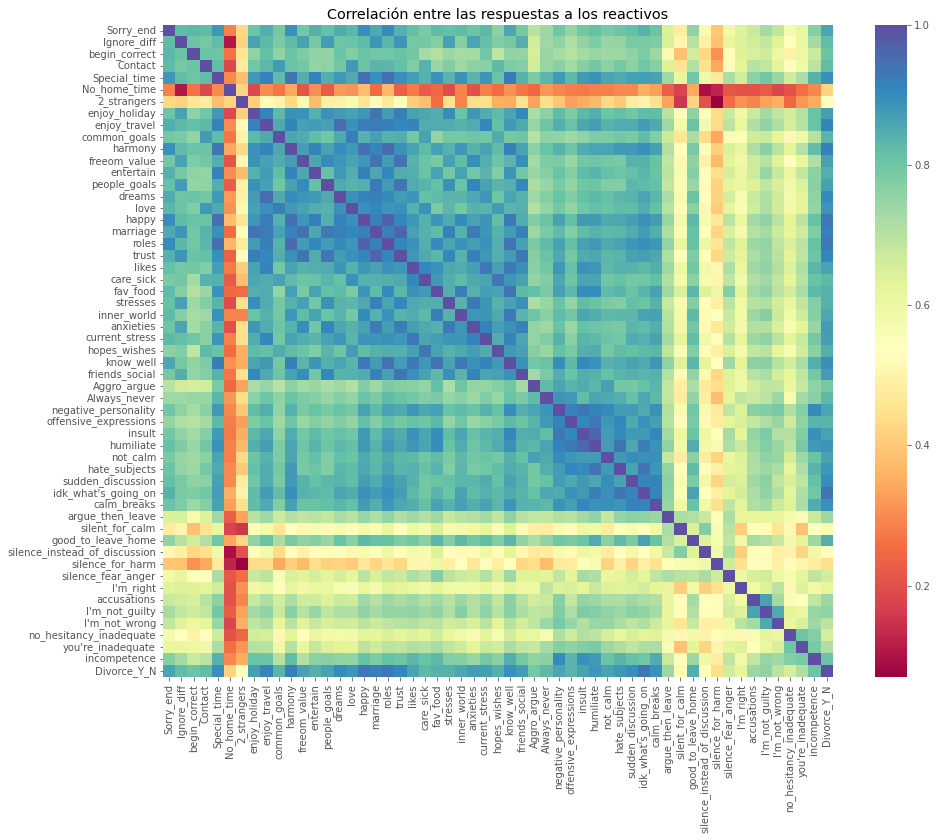

In [9]:
# Correlaciones

plt.figure( figsize = (15, 12) )
sns.heatmap( df.corr(), cmap = 'Spectral' )
plt.title( "Correlación entre las respuestas a los reactivos" )

Como la mayoría de los reactivos están correlacionados entre sí, tiene sentido explorar un análisis factorial.

### Análisis factorial

El análisis factorial es un modelo estadístico lineal que explica la covarianza entre variables observadas mediante un número menor de variables no observadas, los **factores**. Cada variable observada se modela como una combinación lineal de los factores más un error específico (capítulo 3 de las notas).

### ¿Por qué análisis factorial y no PCA?

1. Ambos reducen la dimensión de los datos.
2. PCA es una transformación de los datos que busca reproducir toda la varianza; el análisis factorial es un **modelo** que separa la varianza común (explicada por los factores) de la específica de cada variable.
3. PCA es sobre todo exploratorio; el análisis factorial parte de la hipótesis de que ciertas variables comparten un constructo latente, por lo que es habitual en el análisis de cuestionarios y en investigación de mercados. Con rotaciones oblicuas, además, los factores pueden estar correlacionados.

### Pruebas de adecuación

Antes de estimar se verifica si tiene sentido aplicar el análisis factorial (sección 3.2 de las notas):

**1. Prueba de esfericidad de Bartlett**

**2. Medida de Kaiser–Meyer–Olkin (KMO)**

#### Prueba de esfericidad de Bartlett

$H_0$: la matriz de correlaciones es la identidad.

$H_1$: la matriz de correlaciones no es la identidad.

In [10]:
# Si factor_analyzer no está instalado, ejecute en una celda:
# !pip install factor_analyzer

In [11]:
#
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity


In [12]:
#
data = df.drop('Divorce_Y_N',axis=1)

In [13]:
#
chi2, p = calculate_bartlett_sphericity( data )
print("Ji-cuadrada: ",chi2)
print("Valor p: ",p)

Ji-cuadrada:  17606.430077903202
Valor p:  0.0


**El valor p es menor que 0.05: se rechaza que las variables sean independientes.** Recuerde que esta prueba es una condición necesaria, no suficiente.

### Medida KMO

El KMO compara las correlaciones simples con las parciales. Toma valores entre 0 y 1; según la escala de Kaiser (1974), 0.9 o más es "maravilloso" y menos de 0.5, "inaceptable".

In [14]:
#
from factor_analyzer.factor_analyzer import calculate_kmo


In [15]:
#
kmo_vars,kmo_model = calculate_kmo( data )
print(kmo_model)

0.9643724872807453


**El KMO es cercano a 1**, lo que en principio indica que el análisis factorial es adecuado. Más adelante veremos por qué un buen KMO no basta.

In [16]:
#
from factor_analyzer import FactorAnalyzer


In [17]:
#
n = data.shape[1]
fa = FactorAnalyzer( rotation = None, impute = "drop", n_factors=n)
fa.fit(data)
ev,_ = fa.get_eigenvalues()

ev

array([4.01756867e+01, 2.16531589e+00, 1.41651436e+00, 1.19405368e+00,
       8.96249766e-01, 7.88897467e-01, 6.98636632e-01, 5.95362778e-01,
       5.68366461e-01, 5.29115848e-01, 4.28671399e-01, 3.90369411e-01,
       3.62469358e-01, 3.19198119e-01, 2.83031788e-01, 2.70341457e-01,
       2.52520084e-01, 2.20402276e-01, 2.02203198e-01, 1.91133304e-01,
       1.75596029e-01, 1.65126304e-01, 1.38913064e-01, 1.32199503e-01,
       1.19176457e-01, 1.07826952e-01, 1.03507589e-01, 1.00321611e-01,
       9.48779953e-02, 8.83932265e-02, 7.82819003e-02, 7.10819919e-02,
       6.61273710e-02, 6.21878385e-02, 5.42665704e-02, 5.37969531e-02,
       5.01311101e-02, 4.64030261e-02, 3.99427933e-02, 3.83918809e-02,
       3.53348952e-02, 3.01372243e-02, 2.80488023e-02, 2.49852654e-02,
       2.17052887e-02, 2.16659686e-02, 1.81846648e-02, 1.60713319e-02,
       1.50625288e-02, 1.31196938e-02, 1.19387963e-02, 1.10997856e-02,
       9.73035916e-03, 7.82527366e-03])

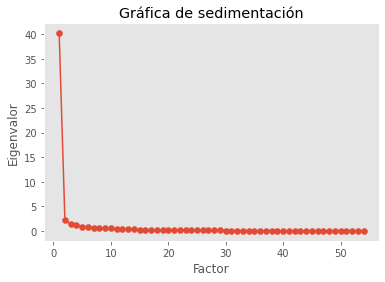

In [18]:
#
plt.scatter( range(1,n+1) , ev)
plt.plot( range(1,n+1) , ev)
plt.title('Gráfica de sedimentación')
plt.xlabel('Factor')
plt.ylabel('Eigenvalor')
plt.grid()

### Cargas factoriales

Las cargas indican qué tanto se relaciona cada variable con cada factor. Ordenarlas ayuda a identificar qué reactivos forman cada factor.

In [19]:
#
fa = FactorAnalyzer( n_factors = 5, rotation = 'varimax' )
fa.fit( data )
fa_load = pd.DataFrame( fa.loadings_ , index=data.columns )

fa_load

,0,1,2,3,4
Sorry_end,0.698027,0.415375,0.251573,0.221070,0.190562
Ignore_diff,0.799304,0.312126,0.248137,0.007242,0.249143
begin_correct,0.685239,0.362436,0.142554,0.229959,0.270391
Contact,0.721785,0.372486,0.181268,0.174657,0.242710
Special_time,0.660066,0.506009,0.377305,0.198270,0.168693
No_home_time,0.087527,0.188128,0.079898,0.574254,-0.039732
2_strangers,0.433963,0.017474,-0.018941,0.567000,0.249501
enjoy_holiday,0.779464,0.399979,0.314565,0.054577,0.152865
enjoy_travel,0.724568,0.405889,0.343090,0.273173,0.175023
common_goals,0.767630,0.352012,0.183620,0.240463,0.133885


In [20]:
def highlight_max(s):
    # Los 10 valores más grandes de la columna
    is_large = s.nlargest(10).values
    # Resaltar si el valor está entre los 10 más grandes
    return ['background-color: yellow' if v in is_large else '' for v in s]

fa_load.sort_values(by=0,ascending=False).style.apply(highlight_max)

,0,1,2,3,4
marriage,0.836865,0.327699,0.292841,0.200275,0.154872
freeom_value,0.828267,0.310767,0.248492,0.167567,0.151989
anxieties,0.805294,0.348423,0.351402,0.059615,0.078859
trust,0.804204,0.380394,0.284953,0.160955,0.201407
people_goals,0.801431,0.333058,0.297584,0.118715,0.132737
Ignore_diff,0.799304,0.312126,0.248137,0.007242,0.249143
enjoy_holiday,0.779464,0.399979,0.314565,0.054577,0.152865
love,0.773158,0.329500,0.264030,0.300530,0.150878
stresses,0.773062,0.367266,0.351396,0.042589,0.140685
common_goals,0.767630,0.352012,0.183620,0.240463,0.133885


In [21]:
#
print(pd.DataFrame(fa.get_factor_variance(),index=['Variance','Proportional Var','Cumulative Var']))

                          0          1         2         3         4
Variance          20.309095  12.237168  7.698707  2.489724  1.823362
Proportional Var   0.376094   0.226614  0.142569  0.046106  0.033766
Cumulative Var     0.376094   0.602709  0.745277  0.791383  0.825149


**Los cinco factores explican cerca del 82.5% de la varianza.** Observe, sin embargo, que el primer eigenvalor (40.2 de 54) domina por completo la gráfica de sedimentación.

### Predicción del divorcio

Usamos los factores como variables explicativas de una regresión logística. Para medir la capacidad predictiva **no** basta con evaluar el modelo en los mismos datos con que se ajustó: esa exactitud es optimista. Usamos validación cruzada estratificada y ajustamos el análisis factorial **dentro** de cada partición de entrenamiento (con un `Pipeline`), para que la información de los datos de prueba no se filtre al modelo.

In [22]:
# Variables y etiqueta
X = data.copy()
y = df['Divorce_Y_N'].copy()
X.shape, y.shape

((170, 54), (170,))

In [23]:
from sklearn.decomposition import FactorAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import classification_report, accuracy_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)

# Modelo 1: cinco factores + regresión logística (el análisis factorial se ajusta en cada partición)
modelo_factores = Pipeline([
    ("factores", FactorAnalysis(n_components=5, rotation="varimax", random_state=0)),
    ("logit", LogisticRegression(max_iter=1000)),
])
# Modelo 2: los 54 reactivos originales
modelo_original = LogisticRegression(max_iter=1000)

for nombre, modelo in [("Cinco factores", modelo_factores), ("54 reactivos", modelo_original)]:
    exact = cross_val_score(modelo, X, y, cv=cv, scoring="accuracy")
    print(f"{nombre:15s} exactitud fuera de muestra: {exact.mean():.3f} (desv. est. {exact.std():.3f})")

Cinco factores  exactitud fuera de muestra: 0.976 (desv. est. 0.022)
54 reactivos    exactitud fuera de muestra: 0.982 (desv. est. 0.014)


In [24]:
# Reporte de clasificación con predicciones fuera de muestra
y_pred = cross_val_predict(modelo_factores, X, y, cv=cv)
print(classification_report(y, y_pred, target_names=["No divorcio", "Divorcio"]))

# Para comparar: la exactitud dentro de la muestra (optimista) del mismo modelo
modelo_factores.fit(X, y)
print(f"Exactitud dentro de la muestra (optimista): {accuracy_score(y, modelo_factores.predict(X)):.3f}")

              precision    recall  f1-score   support

 No divorcio       0.96      1.00      0.98        86
    Divorcio       1.00      0.95      0.98        84

    accuracy                           0.98       170
   macro avg       0.98      0.98      0.98       170
weighted avg       0.98      0.98      0.98       170

Exactitud dentro de la muestra (optimista): 0.976


### Un ejemplo de advertencia (sección 3.8 de las notas)

La clasificación es casi perfecta incluso fuera de muestra. Eso es una pista, no un logro: los dos grupos de parejas responden de forma muy distinta en casi todos los reactivos. Veamos qué mide realmente el primer factor.

In [25]:
from factor_analyzer import FactorAnalyzer

fa1 = FactorAnalyzer(n_factors=1, rotation=None, method="ml")
fa1.fit(data)
f1 = fa1.transform(data)[:, 0]
print(f"Correlación entre el primer factor y haberse divorciado: {abs(np.corrcoef(f1, y)[0, 1]):.2f}")

# Medias por grupo de dos reactivos de conocimiento de la pareja
print(df.groupby("Divorce_Y_N")[["likes", "know_well"]].mean().round(2))

# Alfa de Cronbach de los cuatro reactivos de desprecio, con todas las parejas y sólo con las no divorciadas
def alfa(Xs):
    k = Xs.shape[1]
    return k / (k - 1) * (1 - Xs.var(ddof=1).sum() / Xs.sum(axis=1).var(ddof=1))
desprecio = ["negative_personality", "offensive_expressions", "insult", "humiliate"]
print(f"Alfa (todas las parejas): {alfa(df[desprecio]):.2f}")
print(f"Alfa (sólo no divorciadas): {alfa(df.loc[df.Divorce_Y_N == 0, desprecio]):.2f}")

Correlación entre el primer factor y haberse divorciado: 0.95
             likes  know_well
Divorce_Y_N                  
0             0.15       0.09
1             2.65       2.93
Alfa (todas las parejas): 0.98
Alfa (sólo no divorciadas): 0.56


**Lecciones.**

1. El "factor" dominante es, en esencia, la etiqueta de grupo (divorciados contra no divorciados): cuando la muestra mezcla poblaciones muy distintas, la variación *entre* grupos domina la matriz de correlaciones.
2. Un KMO alto y un alfa alto son condiciones necesarias, no pruebas de validez: dentro de las parejas no divorciadas, la consistencia de los reactivos de desprecio cae mucho.
3. Revise siempre la codificación: "Sé exactamente lo que le gusta a mi pareja" tiene media más alta entre los divorciados, lo contrario de lo que sugiere su redacción.
4. Evalúe la capacidad predictiva fuera de muestra.